### **8. Write and execute programs to remove noise from images using spatial filtering.**

a. Understand 1-D and 2-D convolution process

b. Use 3x3 Mask for low pass filter and high pass filter

In [1]:
import matplotlib.pyplot as plt
from skimage import data, img_as_float
from skimage.filters import sobel, prewitt, scharr, sobel_h, sobel_v
from scipy.ndimage import gaussian_laplace, gaussian_gradient_magnitude
from scipy.signal import convolve2d
import numpy as np

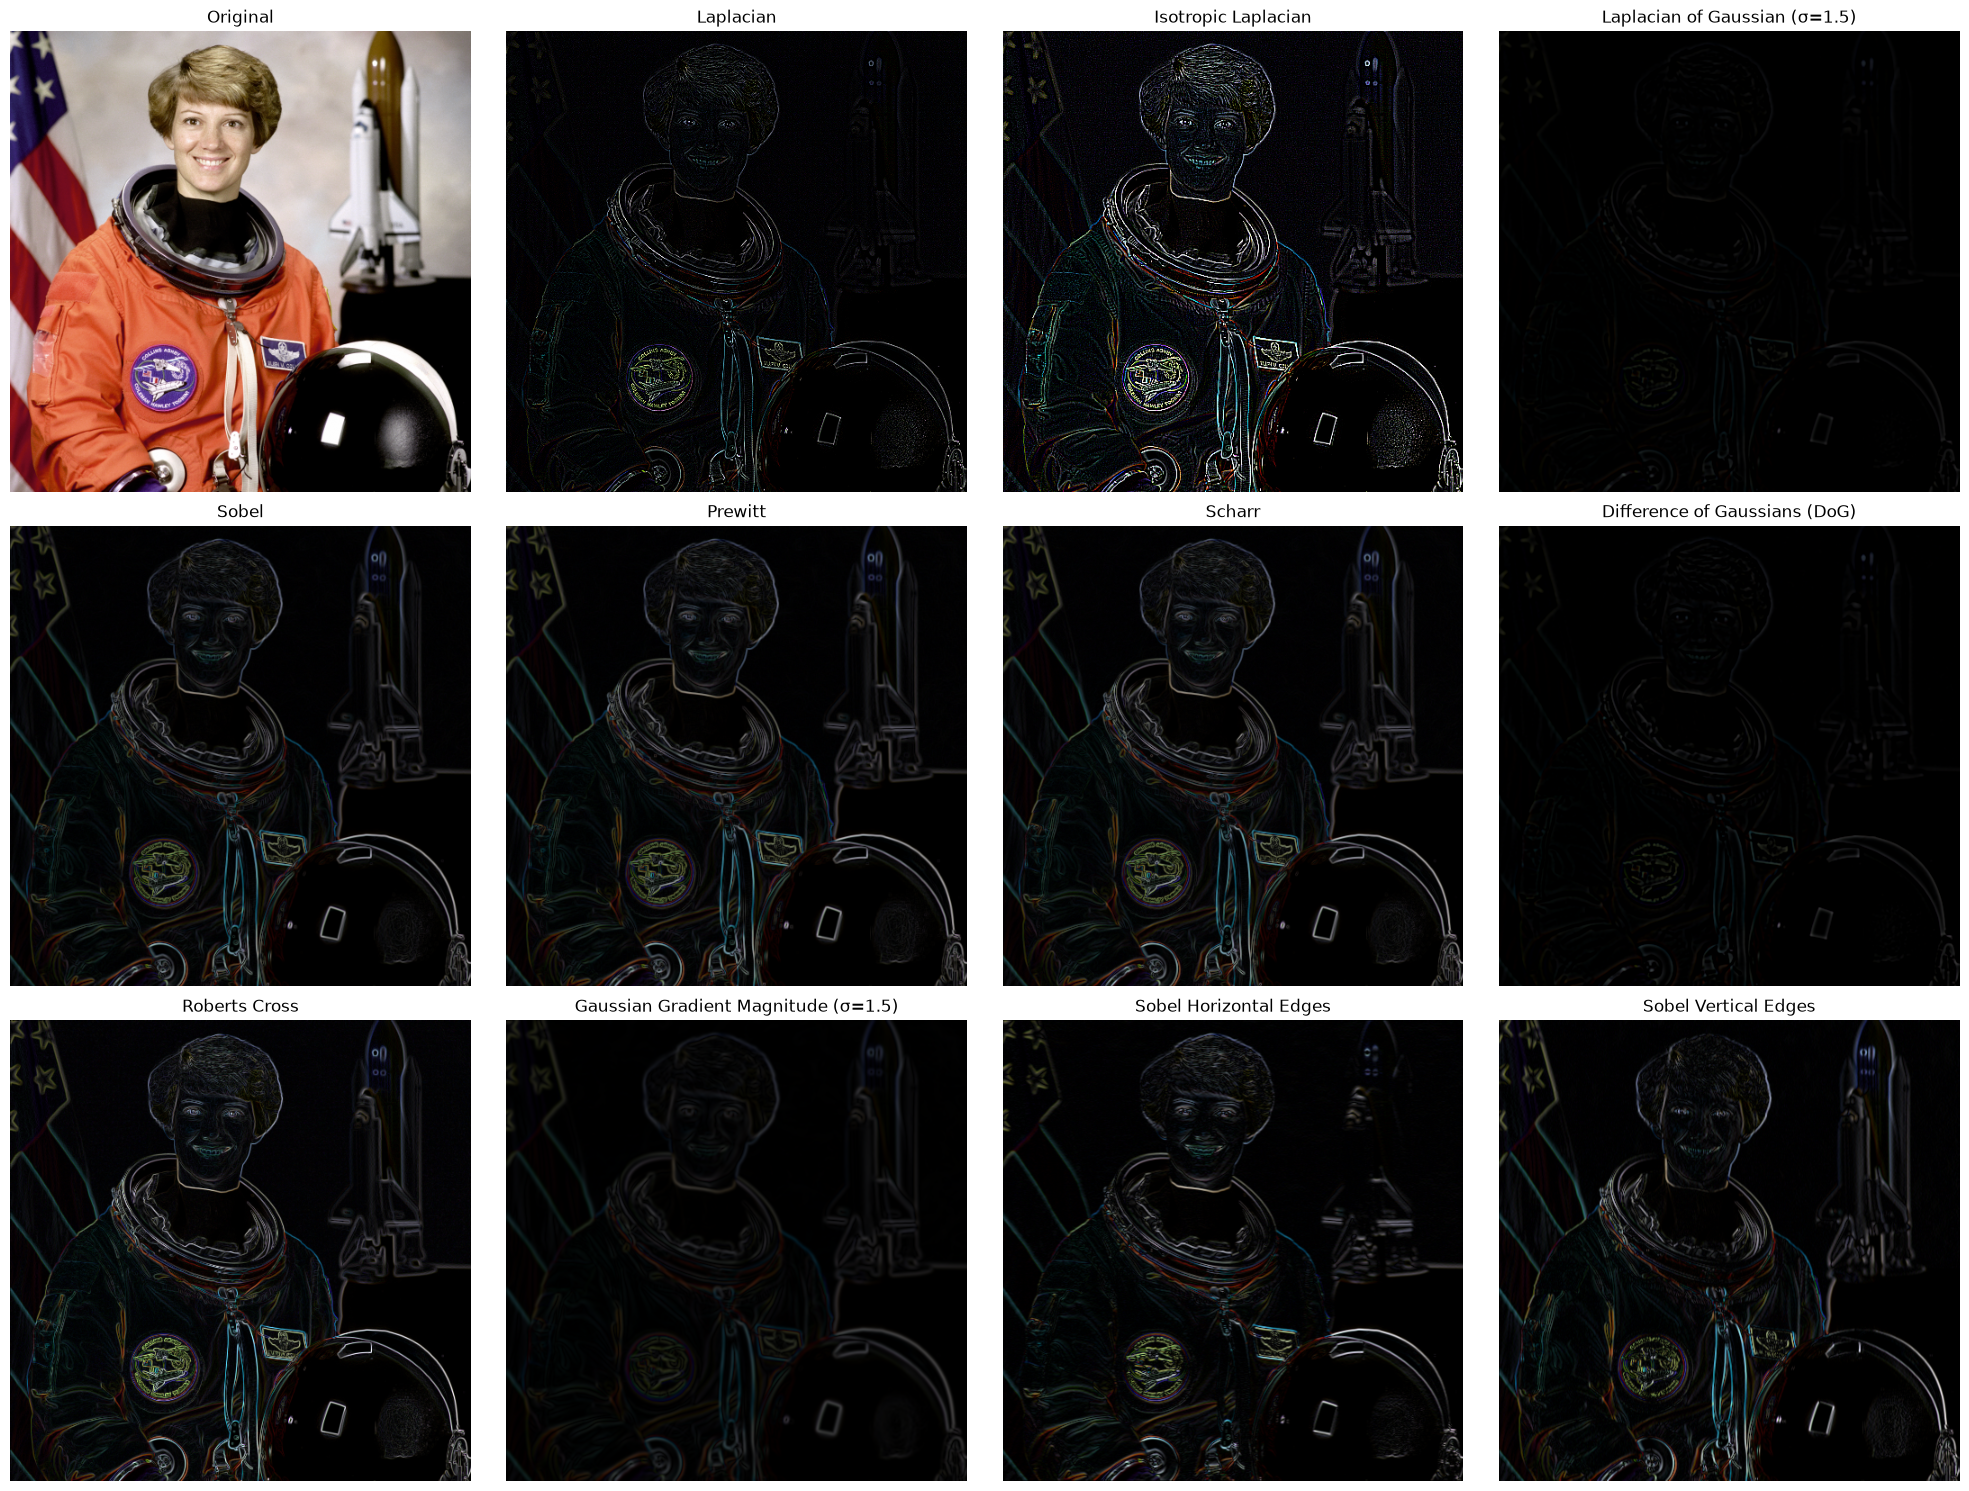

In [2]:
# Load image
astronaut = img_as_float(data.astronaut())

# Helper function to clip image values for display
def clip_img(img):
    return np.clip(img, 0, 1)

# Laplacian kernel (2nd derivative)
laplacian_kernel = np.array([[0, -1, 0],
                             [-1, 4, -1],
                             [0, -1, 0]])

# Isotropic Laplacian kernel (variant)
isotropic_laplacian_kernel = np.array([[-1, -1, -1],
                                       [-1, 8, -1],
                                       [-1, -1, -1]])

# Roberts Cross kernels
roberts_cross_x = np.array([[1, 0],
                            [0, -1]])
roberts_cross_y = np.array([[0, 1],
                            [-1, 0]])

# Difference of Gaussians (DoG) function
def difference_of_gaussians(image, sigma1=1, sigma2=2):
    from scipy.ndimage import gaussian_filter
    low_sigma = gaussian_filter(image, sigma=sigma1)
    high_sigma = gaussian_filter(image, sigma=sigma2)
    return low_sigma - high_sigma

# Apply Laplacian filter
laplacian_filtered = np.zeros_like(astronaut)
for i in range(3):
    laplacian_filtered[..., i] = convolve2d(astronaut[..., i], laplacian_kernel, mode='same', boundary='symm')

# Isotropic Laplacian filter
iso_laplacian_filtered = np.zeros_like(astronaut)
for i in range(3):
    iso_laplacian_filtered[..., i] = convolve2d(astronaut[..., i], isotropic_laplacian_kernel, mode='same', boundary='symm')

# Laplacian of Gaussian (LoG)
sigma_log = 1.5
log_filtered = np.zeros_like(astronaut)
for i in range(3):
    log_filtered[..., i] = -gaussian_laplace(astronaut[..., i], sigma=sigma_log)

# Sobel Filter (from skimage.filters)
sobel_filtered = np.zeros_like(astronaut)
for i in range(3):
    sobel_filtered[..., i] = sobel(astronaut[..., i])

# Prewitt Filter (from skimage.filters)
prewitt_filtered = np.zeros_like(astronaut)
for i in range(3):
    prewitt_filtered[..., i] = prewitt(astronaut[..., i])

# Scharr Filter (from skimage.filters)
scharr_filtered = np.zeros_like(astronaut)
for i in range(3):
    scharr_filtered[..., i] = scharr(astronaut[..., i])

# Difference of Gaussians (DoG)
dog_filtered = np.zeros_like(astronaut)
for i in range(3):
    dog_filtered[..., i] = difference_of_gaussians(astronaut[..., i], sigma1=1, sigma2=2)

# Roberts Cross Filter
roberts_filtered = np.zeros_like(astronaut)
for i in range(3):
    rx = convolve2d(astronaut[..., i], roberts_cross_x, mode='same', boundary='symm')
    ry = convolve2d(astronaut[..., i], roberts_cross_y, mode='same', boundary='symm')
    roberts_filtered[..., i] = np.hypot(rx, ry)

# Gaussian Gradient Magnitude (scipy.ndimage)
sigma_ggm = 1.5
ggm_filtered = np.zeros_like(astronaut)
for i in range(3):
    ggm_filtered[..., i] = gaussian_gradient_magnitude(astronaut[..., i], sigma=sigma_ggm)

# Apply horizontal and vertical Sobel filters
sobel_horizontal = np.zeros_like(astronaut)
sobel_vertical = np.zeros_like(astronaut)
for i in range(3):
    sobel_horizontal[..., i] = sobel_h(astronaut[..., i])
    sobel_vertical[..., i] = sobel_v(astronaut[..., i])

# Create a list of all images and their titles for plotting
filters = [
    (astronaut, "Original"),
    (clip_img(laplacian_filtered), "Laplacian"),
    (clip_img(iso_laplacian_filtered), "Isotropic Laplacian"),
    (clip_img(log_filtered), f"Laplacian of Gaussian (σ={sigma_log})"),
    (clip_img(sobel_filtered), "Sobel"),
    (clip_img(prewitt_filtered), "Prewitt"),
    (clip_img(scharr_filtered), "Scharr"),
    (clip_img(dog_filtered), "Difference of Gaussians (DoG)"),
    (clip_img(roberts_filtered), "Roberts Cross"),
    (clip_img(ggm_filtered), f"Gaussian Gradient Magnitude (σ={sigma_ggm})"),
    (clip_img(np.abs(sobel_horizontal)), "Sobel Horizontal Edges"),
    (clip_img(np.abs(sobel_vertical)), "Sobel Vertical Edges"),
]

# Plotting: Create a 3x4 grid to fit all 12 images
fig, axs = plt.subplots(3, 4, figsize=(20, 15))
axs = axs.ravel()

for ax, (img, title) in zip(axs, filters):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()